In [1]:
import sys
sys.path.append('./src')
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpltPath
import pandas as pd
import random
import cloudpickle as cpk
from chainconsumer import ChainConsumer

import torch
import torch.nn as nn

from sbi import __version__ as sbi_version
from sbi.inference import SNLE
from sbi.utils import BoxUniform
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn, likelihood_nn

from src.load_data import load_data_wide, load_data_narrow
from src.load_data import load_data_wide_realization1, load_data_narrow_realization1
from hyperparameters import hparams

from torch import from_numpy
from torch.utils.data import TensorDataset, DataLoader

from sbi.inference import likelihood_estimator_based_potential
import emcee

torch.cuda.empty_cache


# Set random seeds for reproducibility
RANDOM_SEED = 42

# Set Python random seed
random.seed(RANDOM_SEED)

# Set NumPy random seed
np.random.seed(RANDOM_SEED)

# Set PyTorch random seed
torch.manual_seed(RANDOM_SEED)

# Set CUDA random seed if available
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    # Make CUDA operations deterministic (may impact performance)
    #torch.backends.cudnn.deterministic = True
    #torch.backends.cudnn.benchmark = False

# Set environment variable for additional reproducibility
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)

print(f"SBI version: {sbi_version}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"CUDA deterministic: {torch.backends.cudnn.deterministic}")
print(f"Random seed set to: {RANDOM_SEED}")

training_parameters, training_data = load_data_wide_realization1(hparams)
training_parameters_narrow, training_data_narrow = load_data_narrow_realization1(hparams)
training_parameters = torch.cat((training_parameters,training_parameters_narrow))
training_data = torch.cat((training_data,training_data_narrow))

SBI version: 0.21.0
Using device: cuda
GPU name: NVIDIA A100 80GB PCIe
GPU memory: 85.3 GB
CUDA deterministic: False
Random seed set to: 42


In [81]:
print('creating summary')

##########
# reading in VMIM trained summary network and creatings summaries for the simulations
########
#This worked before, however, I now want to train NLE on a second realization instead of the same first one

#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_5_filters_30_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_inference.pkl', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_inference.pkl', 'rb') as f:
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_mdn_inference.pkl', 'rb') as f:
    inference = cpk.load(f)

train_loader_int, val_loader_int = inference.get_dataloaders(
            training_batch_size=1,
            resume_training=True,
            dataloader_kwargs={"drop_last": False},
        )

#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_5_filters_30_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_density_estimator.pkl', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_density_estimator.pkl', 'rb') as f:
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_mdn_density_estimator.pkl', 'rb') as f:
    density_estimator = cpk.load(f)

train_dataset = TensorDataset(training_parameters, training_data)
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=False,drop_last=False)

#summ = np.empty((2250,2*4*40))
#training_parameters = np.empty((2250,3))

#summ_int = np.empty((2250,2*5*30))
summ_int = np.empty((2250,2*4*40))
training_parameters_int = np.empty((2250,3))

density_estimator._embedding_net.eval()

for i, (param, data, _) in enumerate(train_loader_int):
    summ_int[i] = density_estimator._embedding_net(data).detach().cpu()
    training_parameters_int[i] = param.cpu()
    #summ_int[i] = density_estimator.embed(data).detach().cpu()

creating summary


In [82]:
#summ = np.empty((2500,2*5*30))
summ = np.empty((2500,2*4*40))
training_parameters = np.empty((2500,3))

for i, (param, data) in enumerate(train_loader):
    summ[i] = density_estimator._embedding_net(data).detach().cpu()
    training_parameters[i] = param.cpu()

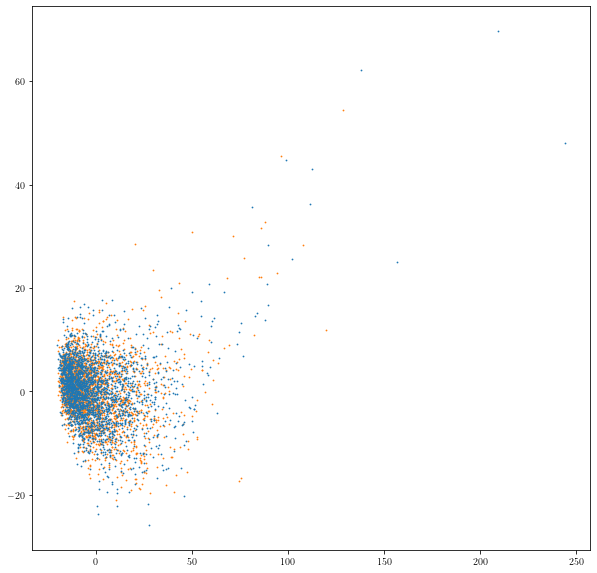

In [89]:
%matplotlib inline
from sklearn.decomposition import PCA
pca = PCA(n_components=30)
summ_int_pca = pca.fit_transform(summ_int)
summ_pca = pca.transform(summ)

fig, ax = plt.subplots(figsize=(10,10))
ax.scatter(*summ_int_pca[:,[0,1]].T,color='tab:orange',s=.6,alpha=1.)
ax.scatter(*summ_pca[:,[0,1]].T,color='tab:blue',s=.6,alpha=1.)
plt.show()

In [90]:
# I can hear you; not anymore
print(np.cumsum(pca.explained_variance_ratio_))

[0.70461344 0.81318194 0.9082244  0.93980003 0.96146606 0.97398864
 0.98080885 0.98638444 0.98913699 0.99138406 0.99317164 0.99448652
 0.99570245 0.9963978  0.99699719 0.99746537 0.99783734 0.99810412
 0.99834586 0.99853564 0.99871079 0.99887836 0.99901854 0.99914201
 0.99923625 0.99932682 0.99940547 0.99947463 0.99953192 0.99958122]


In [91]:
#############
# training NLE with the summary and saving NLE network
###########

#del train_dataset
#del density_estimator
#del train_loader
#del val_loader
#del density_estimator
#del inference
torch.cuda.empty_cache()

lower = np.array([0.1, 0.4, -2.0])
upper = np.array([0.5, 1.4, -0.33])
prior = utils.BoxUniform(low=from_numpy(lower), high=from_numpy(upper),device=hparams.device)

# Define the MAF density estimator
density_estimator = likelihood_nn(
    model='maf',
    num_transforms=5,         # number of MADEs
    num_blocks=3,             # number of layers in each MADE
    hidden_features=128,      # number of hidden units per layer
)

#inference = SNPE_C(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)
inference = SNLE(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)

summ = torch.tensor(summ, dtype=torch.float32)
summ_pca = torch.tensor(summ_pca, dtype=torch.float32)
training_parameters = torch.tensor(training_parameters, dtype=torch.float32)



density_estimator = inference.append_simulations(training_parameters, summ_pca).train(
    training_batch_size=32, 
    learning_rate=1e-4, 
    stop_after_epochs=20,
    max_num_epochs=1024,
    show_train_summary=True
)

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(
/scratch-local/slurm-job-tmp-11551220/ipykernel_891/2557568917.py:28: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  summ = torch.tensor(summ, dtype=torch.float32)
/scratch-local/slurm-job-tmp-11551220/ipykernel_891/2557568917.py:30: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  training_parame

 Neural network successfully converged after 283 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 283
        Best validation performance: 4.0820
        -------------------------
        


In [92]:
# change
testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_new.npy')
testing_summ_pca = pca.transform(testing_summ)
#testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_new_5.npy')
#testing_summ_pca = pca.transform(testing_summ)
#testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_mdn_new.npy')


######
# sampling
########
boundary_Om_sig8 = np.array([
    [0.1, 1.4],
    [0.2, 1.4],
    [0.5, 0.65],
    [0.5, 0.4],
    [0.3, 0.4],
    [0.1, 0.9],])
boundary_Om_w0 = np.array([
    [.1, -1.1],
    [.5, -2.],
    [.5, -.33],
    [.1, -.33],])
validOS = mpltPath.Path(boundary_Om_sig8)
validOW = mpltPath.Path(boundary_Om_w0)
potential_fn, parameter_transform = likelihood_estimator_based_potential(density_estimator, prior, testing_summ_pca[0]) # density_estimator is you trained flow, prior is just the sbi box_prior
def log_prob(args):
    pot = np.array(potential_fn(torch.Tensor(args).to(device)).tolist())
    #pot[~validOS.contains_points(args[:,[0,4]])] = -np.inf #change indices to Om, s8
    #pot[~validOW.contains_points(args[:,[0,5]])] = -np.inf ##change indices to Om, w0
    pot[~validOS.contains_points(args[:,[0,1]])] = -np.inf #change indices to Om, s8
    pot[~validOW.contains_points(args[:,[0,2]])] = -np.inf ##change indices to Om, w0
    return pot
#theta_0 =  CGPrior.sample(nwalkers).detach().cpu().numpy() #Just replace this with some random initial points
nwalkers = 16
ndim = 3
theta_0 = np.random.uniform([.1,.7,-1.1],[.4,.9,-.9],(nwalkers,3))
#nsteps = 100000
nsteps = 20000
discard = 1000
step = 1
nflows = 1 #???
tot_steps = nflows * nsteps * step + discard
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, vectorize=True)
state = sampler.run_mcmc(theta_0, tot_steps, progress=True)
samples = sampler.get_chain(discard=discard, thin=step, flat=True) 
#samples = remove_invalid_points(samples)
print(samples.shape)

100%|██████████| 21000/21000 [01:59<00:00, 176.26it/s]

(320000, 3)


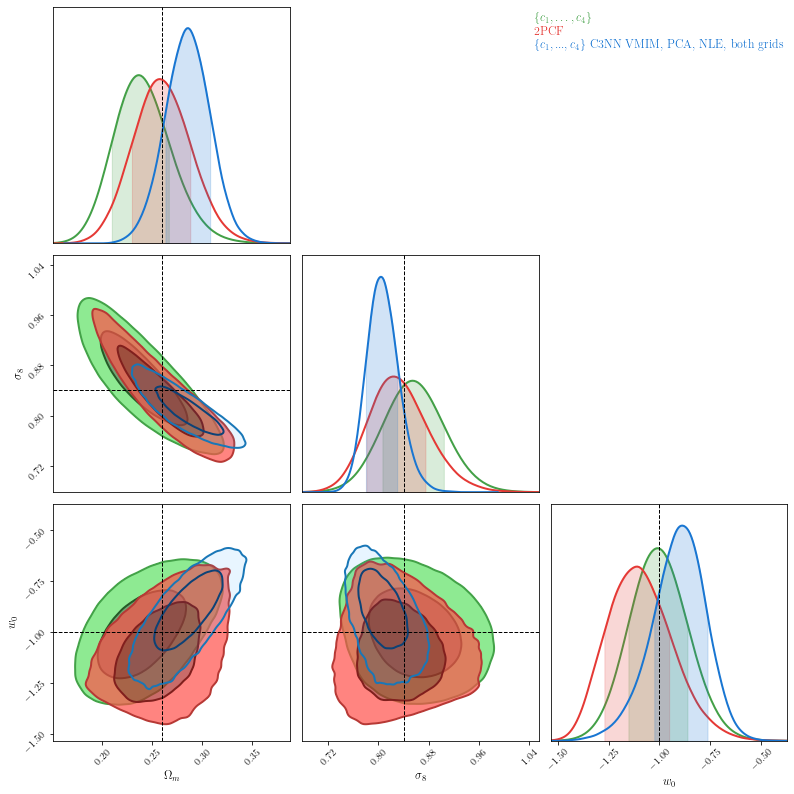

In [94]:
########
# plotting
########

sample_c4 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]

c = ChainConsumer()

c.add_chain(sample_c4, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$ ', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_2PCF, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'2PCF', shade=True, shade_alpha=0.7, color='red', linestyle='-', linewidth=2.0, kde=False)
# change
c.add_chain(samples, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, ..., c_4\}$ '+'C3NN VMIM, PCA, NLE, both grids', shade=True, shade_alpha=0.1, color='blue', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_5, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, ..., c_5\}$ '+'C3NN VMIM, PCA, NLE, both grids', shade=True, shade_alpha=0.1, color='grey', linestyle='-', linewidth=2.0, kde=False)


fig = c.plotter.plot(figsize=(12, 12), truth=[0.26, 0.84, -1], legend=True)

# change
#plt.savefig('Plots/C3NN_NLE_newsampling_new_realization1_5.png')
#plt.savefig('Plots/C3NN_NLE_newsampling_new_realization2.png')
#plt.savefig('Plots/C3NN_NLE_newsampling_mdn_new.png')
plt.savefig('Plots/c4_2pt_c4nle_30pcs.pdf')
plt.show()

In [80]:
print(np.std(samples,axis=0))
print(np.std(samples_2PCF, axis=0))
print(np.std(samples_2PCF,axis=0)/np.std(samples, axis=0)-1)

[0.02000786 0.03202809 0.1799496 ]
[0.02896152 0.04740774 0.15851219]
[ 0.44750668  0.48019264 -0.11913008]


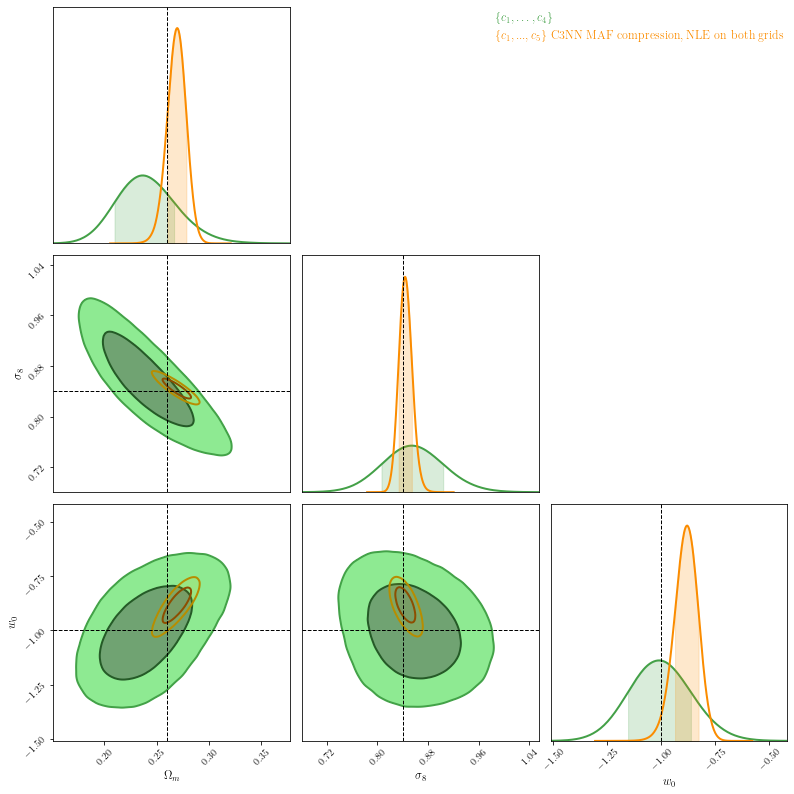

In [32]:
fig

In [ ]:
# now sample to run sbc


In [97]:
from sbi.analysis import run_sbc


train_loader_nle, val_loader_nle = inference.get_dataloaders(
            training_batch_size=1,
            resume_training=True,
            dataloader_kwargs={"drop_last": False},
        )

samples = np.empty((250,3))
params_val = np.empty((250,3))
data_val = np.empty((250,30))
for i, (param, data, _) in enumerate(val_loader_nle):
    params_val[i] = param.cpu()
    data_val[i] = data.cpu()
    #sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, vectorize=True)
    #state = sampler.run_mcmc(theta_0, tot_steps, progress=True)
    #samples[i] = sampler.get_chain(discard=discard, thin=step, flat=True) 


def plot_ranks_cdf(rank,rank_val):
    
    plt.clf()

    fig, ax = plt.subplots(1,2,figsize=(8,4))
    fig, ax[0] = sbc_rank_plot(
        ranks=rank,
        num_posterior_samples=num_posterior_samples,
        plot_type="cdf",
        num_bins=None,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=['$\Omega_m$','$\sigma_8$'],
        fig = fig,
        ax = ax[0]
    )
    fig, ax[1] = sbc_rank_plot(
        ranks=rank_val,
        num_posterior_samples=num_posterior_samples,
        plot_type="cdf",
        num_bins=None,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=['$\Omega_m \mathrm{Validation\ Set}$','$\sigma_8 \mathrm{Validation\ Set}$'],
        fig = fig,
        ax = ax[1]
    )

    for axis in ax:
        axis.set_xlabel('$\mathrm{Posterior\ Rank}$')
    ax[0].set_ylabel('$\mathrm{Empirical\ CDF}$')
    ax[1].set_ylabel('')
    ax[0].set_yticks([0,.5,1],[r'$0$',r'$0.5$',r'$1$'])
    ax[1].set_yticks([0,.5,1],[r'$0$',r'$0.5$',r'$1$'])

In [108]:
import tqdm
import time
num_posterior_samples=4

posterior = inference.build_posterior()

time1 = time.time()
ranks, dap_samples = run_sbc(
    torch.tensor(params_val[:2]).to('cuda'), torch.tensor(data_val[:2]).to('cuda'), posterior, num_posterior_samples=num_posterior_samples,
)
time2 = time.time()

print(time2-time1)
sys.exit()
ranks_val, dap_samples = run_sbc(
    torch.tensor(params_val), torch.tensor(data_val), posterior, num_posterior_samples=num_posterior_samples,
)

plot_ranks_cdf(ranks,ranks_val)
plt.show()

Running 2 sbc samples.:   0%|          | 0/2 [00:00<?, ?it/s]

120.20821046829224


SystemExit: 

In [101]:
data_val.shape

(250, 30)

In [ ]:
#likelihood_estimator = inference.get_density_estimator()
model_dir = f"/project/ag-weller/Kai.Lehman/C3NN_Models/"
with open(f"{model_dir}/nle_widenarrow_inference_new_realization1.pkl", "wb") as handle:
#with open(f"{model_dir}/nle_widenarrow_mdn_inference_new.pkl", "wb") as handle:
    cpk.dump(inference, handle)
with open(f"{model_dir}/nle_widenarrow_density_estimator_new_realization1.pkl", "wb") as handle:
#with open(f"{model_dir}/nle_widenarrow_mdn_density_estimator_new.pkl", "wb") as handle:
    cpk.dump(density_estimator, handle)

posterior = inference.build_posterior()

NameError: name 'np' is not defined